## Problema y objetivos

La empresa quiere identificar el género de una canción a partir de sus características de audio. La variable `id_genero` no es una etiqueta de sí o no, ni un valor numérico a estimar: toma 10 valores distintos y cada canción pertenece a una sola clase. El problema es de **clasificación supervisada multiclase**.

En este notebook el objetivo es entrenar una red neuronal artificial que, a partir de las características de 30 segundos de cada canción, le asigne una de esas 10 clases. El modelo se ajusta solo con las canciones de entrenamiento; el conjunto de test se reserva para la evaluación. El resultado se mide con accuracy y F1 macro, para ver el acierto global y el rendimiento medio entre géneros.

## Selección de métricas y umbral

**Accuracy.** Hay 10 géneros y el mismo número de canciones en cada clase. Con ese reparto equilibrado, el porcentaje de aciertos resume el rendimiento global sin que una clase más frecuente lo distorsione.

**F1 macro.** Se calcula el F1 de cada género y se promedia dando el mismo peso a las 10 clases. Así, un género fácil de clasificar no compensa a otro que el modelo confunde. El F1 por clase del informe de clasificación muestra cuáles son esos géneros.

**Umbral de decisión.** El modelo devuelve una probabilidad para cada una de las 10 clases. La clase asignada es la de probabilidad más alta. No se exige una probabilidad mínima para aceptar la predicción: si la clase ganadora tiene, por ejemplo, 0,2 y el resto queda por debajo, esa clase se predice igualmente.

In [1]:
!pip install tensorflow

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

In [3]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

#Cargamos los datos, y la seleccion que hemos decidido para train y test
df = pd.read_csv(DATOS / "df_cancion_30s.csv")
ids_train = pd.read_csv(DATOS / "ids_train.csv")['id_cancion']
ids_test = pd.read_csv(DATOS / "ids_test.csv")['id_cancion']

In [4]:
df

,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica,filename_30s,length_30s,...,mfcc16_var_30s,mfcc17_mean_30s,mfcc17_var_30s,mfcc18_mean_30s,mfcc18_var_30s,mfcc19_mean_30s,mfcc19_var_30s,mfcc20_mean_30s,mfcc20_var_30s,label_30s
0,1,blues.00000.wav,138.0,744.01,1,1,1,1,blues.00000.wav,661794,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,2,blues.00001.wav,142.0,4178.85,1,2,2,2,blues.00001.wav,661794,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,3,blues.00002.wav,96.0,3226.40,1,3,4,3,blues.00002.wav,661794,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,4,blues.00003.wav,111.0,3618.77,1,4,6,4,blues.00003.wav,661794,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,5,blues.00004.wav,191.0,1990.81,1,5,7,5,blues.00004.wav,661794,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,rock.00095.wav,101.0,3185.88,10,197,306,25,rock.00095.wav,661794,...,45.050526,-13.289984,41.754955,2.484145,36.778877,-6.713265,54.866825,-1.193787,49.950665,rock
996,997,rock.00096.wav,170.0,-503.65,10,194,321,1,rock.00096.wav,661794,...,33.851742,-10.848309,39.395096,1.881229,32.010040,-7.461491,39.196327,-2.795338,31.773624,rock
997,998,rock.00097.wav,121.0,2170.05,10,189,297,9,rock.00097.wav,661794,...,33.597008,-12.845291,36.367264,3.440978,36.001110,-12.588070,42.502201,-2.106337,29.865515,rock
998,999,rock.00098.wav,99.0,1425.79,10,187,301,20,rock.00098.wav,661794,...,46.324894,-4.416050,43.583942,1.556207,34.331261,-5.041897,47.227180,-3.590644,41.299088,rock


#Preparación de los datos

In [5]:
#Este modelo no acepta nulos, veamos donde hay
df.columns[df.isnull().sum()>0]

Index(['duracion'], dtype='object')

In [6]:
df['duracion'].isnull().sum()

np.int64(18)

Durante el EDA se identificaron estos valores nulos en la variable duración. El análisis de los registros asociados permitió comprobar
que dichas canciones tenían una duración de 30 segundos, por lo que los valores faltantes se imputarán con ese valor.

In [7]:
df['duracion'] = df['duracion'].fillna(30)

In [8]:
#Separamos en train/test
df_train = df[df['id_cancion'].isin(ids_train)].copy()
df_test = df[df['id_cancion'].isin(ids_test)].copy()

In [9]:
#Para este modelo se utilizan únicamente variables numéricas. Las columnas de tipo object y los identificadores se eliminan para evitar
#problemas de codificación y reducir ruido en el entrenamiento.
X_train = df_train.drop(columns=['id_genero','cancion','filename_30s','label_30s','id_cancion','id_disco','id_autor','id_discografica'])
y_train = df_train['id_genero']
X_test = df_test.drop(columns=['id_genero','cancion','filename_30s','label_30s','id_cancion','id_disco','id_autor','id_discografica'])
y_test = df_test['id_genero']

## División de entrenamiento y validación

Se reserva un 20 % de las canciones de entrenamiento para validación. El conjunto de test no interviene en el entrenamiento y se reserva para la evaluación final.

In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train,
)
print("Train:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (640, 60) (640,)
Validación: (160, 60) (160,)
Test: (200, 60) (200,)


In [11]:
#Estandarizamos los datos. El escalado se ajusta solo con el conjunto de entrenamiento.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [12]:
#Codificamos la variable y para cambiar el rango de 1-10 a 0-9, y así garantizar la compatibilidad con el algoritmo
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_val = le.transform(y_val)
y_test = le.transform(y_test)

#Construcción del modelo ANN

In [13]:
X_train_scaled.shape

(640, 60)

In [14]:
model = keras.Sequential([
    layers.Dense(64, activation=tf.nn.relu, input_shape=[X_train_scaled.shape[1]], name='h1'),
    layers.Dropout(0.2),
    layers.Dense(32, activation=tf.nn.relu, name='h2'),
    layers.Dropout(0.2),
    layers.Dense(10, activation=tf.nn.softmax, name='o')
  ])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ h1 (Dense)                      │ (None, 64)             │         3,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ h2 (Dense)                      │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ o (Dense)                       │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,314 (24.66 KB)

 Trainable params: 6,314 (24.66 KB)

 Non-trainable params: 0 (0.00 B)

#Entrenamiento del modelo

In [15]:
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    validation_data=(X_val_scaled, y_val),
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.1500 - loss: 2.3506 - val_accuracy: 0.2562 - val_loss: 2.1163
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2672 - loss: 2.0649 - val_accuracy: 0.2937 - val_loss: 1.9290
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3047 - loss: 1.9023 - val_accuracy: 0.3812 - val_loss: 1.7958
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3359 - loss: 1.7809 - val_accuracy: 0.4313 - val_loss: 1.6853
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4375 - loss: 1.6171 - val_accuracy: 0.4563 - val_loss: 1.5755
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5031 - loss: 1.4796 - val_accuracy: 0.5063 - val_loss: 1.4625
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5047 - loss: 1.4291 - val_accuracy: 0.5312 - val_loss: 1.3747
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5172 - loss: 1.3808 - val_accuracy: 0.5437 - v

#Evaluación y predicción del modelo

In [16]:
#Precisión entrenamiento
train_loss, train_accuracy = model.evaluate(
    X_train_scaled,
    y_train,
    verbose=0
)

#Precisión test
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Precisión entrenamiento: {train_accuracy:.4f}")
print(f"Loss entrenamiento: {train_loss:.4f}")
print(f"Precisión prueba: {test_accuracy:.4f}")
print(f"Loss prueba: {test_loss:.4f}")

Precisión entrenamiento: 0.9328
Loss entrenamiento: 0.2682
Precisión prueba: 0.7050
Loss prueba: 0.9208


In [17]:
y_pred_ann = np.argmax(
    model.predict(X_test_scaled),
    axis=1)
y_pred_ann

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


array([2, 0, 0, 5, 0, 5, 0, 0, 0, 8, 6, 0, 9, 0, 0, 0, 8, 0, 2, 8, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 5, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 0, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 8, 2, 2, 2, 2, 2, 4, 3, 8, 9, 3, 7,
       4, 7, 3, 1, 3, 3, 3, 9, 4, 3, 9, 4, 3, 8, 8, 4, 4, 0, 4, 4, 4, 4,
       4, 4, 4, 4, 4, 4, 8, 4, 4, 4, 4, 8, 1, 0, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 9, 1, 5, 5, 6, 6, 6, 6, 6, 6, 0, 6, 6, 6, 6, 6,
       6, 3, 6, 6, 6, 0, 4, 6, 7, 7, 8, 3, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 8, 7, 7, 7, 7, 8, 8, 8, 4, 8, 8, 8, 8, 9, 4, 8, 4, 8, 8, 8, 8,
       3, 8, 9, 8, 9, 2, 9, 2, 2, 6, 2, 7, 3, 2, 3, 5, 5, 8, 9, 9, 9, 9,
       9, 2])

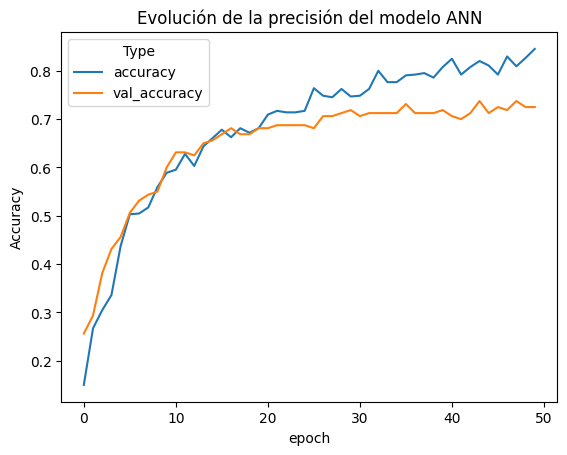

In [18]:
hist = pd.DataFrame(history.history)
#Incluye la epoca para cada error
hist['epoch'] = history.epoch

#Colpasa los errores 'mean_absolute_error','val_mean_absolute_error' en una sola columna para sns
df = hist.melt(id_vars='epoch', var_name='Type', value_name='Accuracy',
               value_vars=['accuracy','val_accuracy'])
#Gráfico de las respuestas para distintos eventos y regiones
_ = sns.lineplot(x='epoch', y='Accuracy', hue='Type', data=df)
_.set_title('Evolución de la precisión del modelo ANN')
plt.show()


A partir de aproximadamente la época 25-30, la precisión de entrenamiento continúa aumentando mientras que la precisión de validación permanece prácticamente estable. Este comportamiento constituye una evidencia visual del sobreajuste del modelo.

In [19]:
#Deshacemos el LabelEncoder
y_pred_original = le.inverse_transform(y_pred_ann)
y_test_original = le.inverse_transform(y_test)

In [20]:
print(classification_report(y_test_original, y_pred_original))

              precision    recall  f1-score   support

           1       0.65      0.55      0.59        20
           2       0.86      0.95      0.90        20
           3       0.68      0.85      0.76        20
           4       0.62      0.40      0.48        20
           5       0.67      0.80      0.73        20
           6       0.76      0.80      0.78        20
           7       0.89      0.80      0.84        20
           8       0.85      0.85      0.85        20
           9       0.54      0.70      0.61        20
          10       0.50      0.35      0.41        20

    accuracy                           0.70       200
   macro avg       0.70      0.70      0.70       200
weighted avg       0.70      0.70      0.70       200



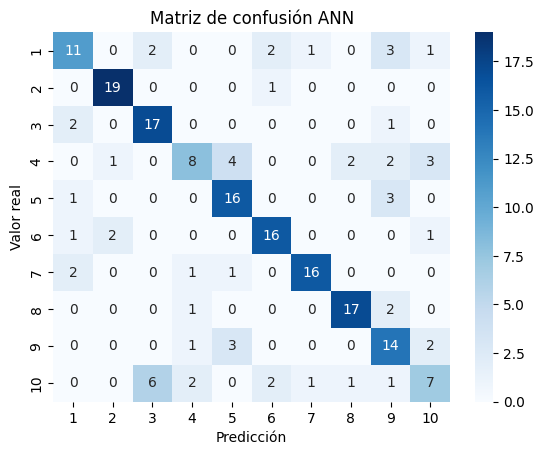

In [21]:
#Matriz de confusión
cm = confusion_matrix(y_test_original, y_pred_original)

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=np.unique(y_test_original),
            yticklabels=np.unique(y_test_original))

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión ANN")
plt.show()

#Conclusiones

La red neuronal artificial (ANN) alcanzó una precisión del 93,3% en el conjunto de entrenamiento y del 70,5% en el conjunto de prueba, con valores de pérdida de 0,2682 y 0,9208, respectivamente. La evolución de la precisión muestra una mejora progresiva durante las primeras épocas, estabilizándose posteriormente alrededor del 70% en el conjunto de validación. La diferencia entre las métricas de entrenamiento y prueba indica la existencia de cierto sobreajuste, aunque el modelo mantiene una capacidad de generalización aceptable sobre datos no vistos.

El análisis del Classification Report muestra un rendimiento desigual según el género musical. Algunas clases, como las correspondientes a los identificadores 2, 7 y 8, presentan valores de precision, recall y F1-score elevados, mientras que otras, como las clases 4 y 10, obtienen resultados más modestos. La matriz de confusión confirma esta situación, observándose varias confusiones entre determinados géneros, especialmente en las clases con menor precisión y recall.

En conjunto, el modelo ANN logra un rendimiento razonable aunque presenta margen de mejora debido al sobreajuste detectado. Aun así, alcanza una precisión superior al 70 % sobre datos de prueba, lo que demuestra su capacidad para identificar patrones relevantes en las características de audio utilizadas para la clasificación de géneros musicales.